# Rainfall projections

Multi-model CMIP6 projections prepared by CSIRO on a common 1° Pacific grid. Every model's annual series is averaged over each EEZ and over all the EEZs together (cosine-of-latitude weights) and expressed as the change relative to its own 2015–2035 mean. For each indicator:

* **Trend map** — linear trend over 2015–2100 of the multi-model median change in each EEZ, one panel per scenario.
* **Warming-level map** — multi-model median change in each EEZ in the year each scenario first reaches each global warming level, one figure per scenario on a shared colour scale.
* **All-EEZ box plots** — spread across models at each warming level for the mean over all the Pacific EEZs.

```{glue:figure} pr_fig
:scale: 60%
:align: center
```

**Figure. Change in total rainfall relative to 2015–2035 in each Pacific EEZ at the global warming levels** (multi-model median, `map_scenario`).

In [1]:
# CIndRA notebook display standard
import matplotlib as mpl

mpl.rcParams.update({
    'font.size': 12,
    'axes.titlesize': 15,
    'axes.labelsize': 14,
    'xtick.labelsize': 12,
    'ytick.labelsize': 12,
    'legend.fontsize': 13,
    'figure.dpi': 100,
    'savefig.dpi': 150,
})

## Setup

Regional helpers come from `functions/projections_regional.py` (EEZ and all-EEZ means, maps, box plots) and `functions/projections.py` (data access, warming levels); the box plots use `ind_setup.plotting_projections` from the [indicators_setup](https://github.com/lauracagigal/indicators_setup) repository.

In [2]:
import warnings
warnings.filterwarnings("ignore")

import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from myst_nb import glue

sys.path.append("../../../../../../indicators_setup")
sys.path.append("../../../../functions")
import projections as prj
import projections_regional as reg

### Configuration

Scenarios and global warming levels are the ones of the national projections ([`../../National/00_warming_levels.ipynb`](../../National/00_warming_levels.ipynb)). Maps of the change at warming levels are drawn for every scenario on a shared colour scale (`map_scenario` is the one shown at the top of the notebook); box plots show every scenario. Figures go to `outputs/figures/regional_pacific/PRJ_*` and tables to `outputs/tables/regional_pacific/PRJ_*`.

In [3]:
ssp_scenarios = ['ssp126', 'ssp245', 'ssp370', 'ssp585']
map_scenario = "ssp370"
scenario_info = prj.load_warming_levels(ssp_scenarios)

eez = reg.load_eez()
fig_dir = Path("../../../../outputs/figures/regional_pacific")
tables_dir = Path("../../../../outputs/tables/regional_pacific")
fig_dir.mkdir(parents=True, exist_ok=True)
tables_dir.mkdir(parents=True, exist_ok=True)

## Total rainfall

Annual total rainfall (sum of monthly totals), change in %.

**Annual rainfall: linear trend 2015–2100 of the multi-model median (% per decade), by EEZ**

,SSP126,SSP245,SSP370,SSP585
American Samoa,-0.077,-0.076,0.187,-0.104
Cook Islands,0.106,0.067,0.364,0.122
Fiji,-0.268,-0.100,0.104,0.004
French Polynesia,-0.096,-0.138,-0.315,-0.767
Hawaii,-0.198,-0.419,0.171,0.405
Howland Island and Baker Island,2.009,4.712,7.346,11.327
Jarvis Island,2.419,6.448,10.915,17.008
Johnston Atoll,-0.294,0.564,1.573,2.182
Kiribati,1.830,4.341,5.989,7.935
Line Group,0.653,1.607,2.257,3.375


**Change in annual rainfall vs 2015–2035 at the global warming levels (SSP126, multi-model median, %), by EEZ**

,+1.5°C (2032)
region,
American Samoa,1.94
Cook Islands,-0.42
Fiji,2.87
French Polynesia,0.07
Hawaii,-4.91
Howland Island and Baker Island,-23.18
Jarvis Island,-40.29
Johnston Atoll,2.56
Kiribati,-15.78


**Change in annual rainfall vs 2015–2035 at the global warming levels (SSP245, multi-model median, %), by EEZ**

,+1.5°C (2030),+2.0°C (2052),+2.5°C (2079)
region,,,
American Samoa,-2.26,2.05,2.17
Cook Islands,-0.77,1.46,0.38
Fiji,1.11,3.63,-2.21
French Polynesia,-0.20,-2.04,-3.43
Hawaii,-3.36,-6.84,-4.14
Howland Island and Baker Island,-27.38,9.88,19.68
Jarvis Island,-44.76,8.37,8.70
Johnston Atoll,11.66,-12.60,3.54
Kiribati,-23.47,8.57,14.16


... (2 outputs left out)

**Change in annual rainfall vs 2015–2035 at the global warming levels (SSP585, multi-model median, %), by EEZ**

,+1.5°C (2027),+2.0°C (2041),+2.5°C (2053),+3.0°C (2064)
region,,,,
American Samoa,1.94,2.58,-2.21,-3.42
Cook Islands,-2.28,3.55,2.85,-2.72
Fiji,0.35,0.72,-5.67,0.73
French Polynesia,-0.19,0.37,0.08,-5.38
Hawaii,-5.15,-3.76,-2.72,-2.17
Howland Island and Baker Island,-23.64,-19.12,4.44,14.11
Jarvis Island,-25.32,-29.65,-3.87,9.50
Johnston Atoll,-10.52,8.78,2.95,7.71
Kiribati,-10.37,-15.27,12.50,16.74


**Change in annual rainfall vs 2015–2035 at the global warming levels (%): spread across models in All Pacific EEZs**

,Region,Scenario,Warming level,Year,Models,Median,P10,P90,Min,Max
0,All Pacific EEZs,SSP126,+1.5°C,2032,36,0.45,-4.91,7.65,-13.37,10.30
1,All Pacific EEZs,SSP126,+2.0°C,<NA>,0,NaN,NaN,NaN,NaN,NaN
2,All Pacific EEZs,SSP126,+2.5°C,<NA>,0,NaN,NaN,NaN,NaN,NaN
3,All Pacific EEZs,SSP126,+3.0°C,<NA>,0,NaN,NaN,NaN,NaN,NaN
4,All Pacific EEZs,SSP245,+1.5°C,2030,36,-1.41,-9.05,5.93,-14.73,10.95
5,All Pacific EEZs,SSP245,+2.0°C,2052,36,2.31,-3.85,8.63,-8.50,12.79
6,All Pacific EEZs,SSP245,+2.5°C,2079,36,3.10,-4.28,11.56,-12.31,12.45
7,All Pacific EEZs,SSP245,+3.0°C,<NA>,0,NaN,NaN,NaN,NaN,NaN
8,All Pacific EEZs,SSP370,+1.5°C,2030,36,0.17,-8.10,4.52,-12.88,7.49
9,All Pacific EEZs,SSP370,+2.0°C,2046,36,2.70,-4.29,8.97,-10.28,10.93


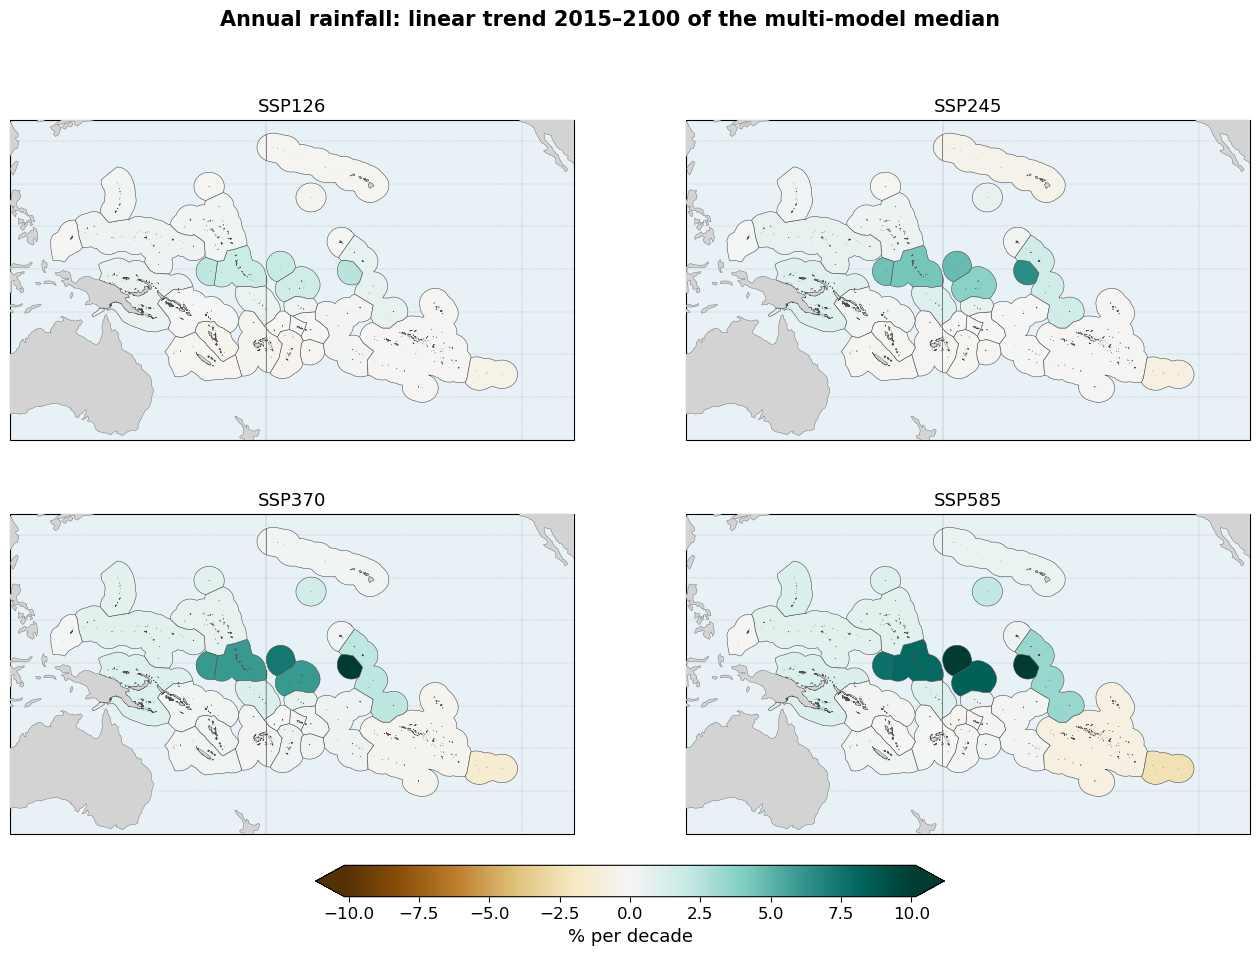

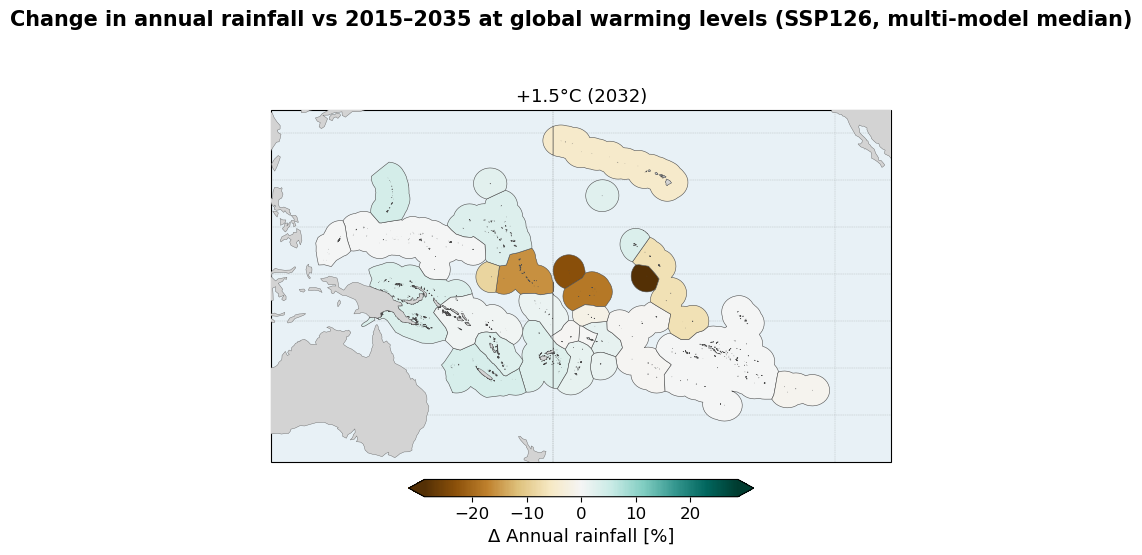

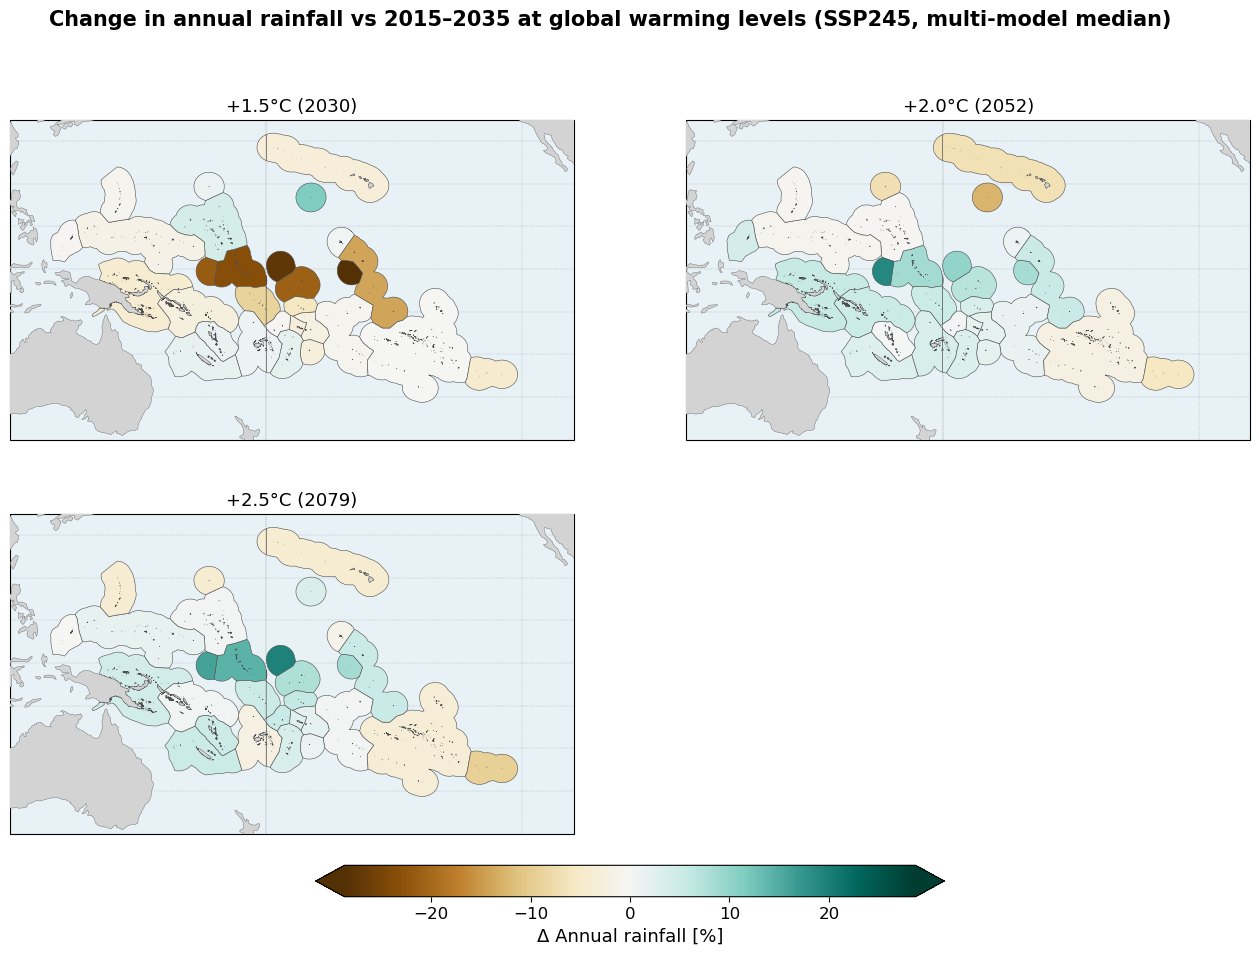

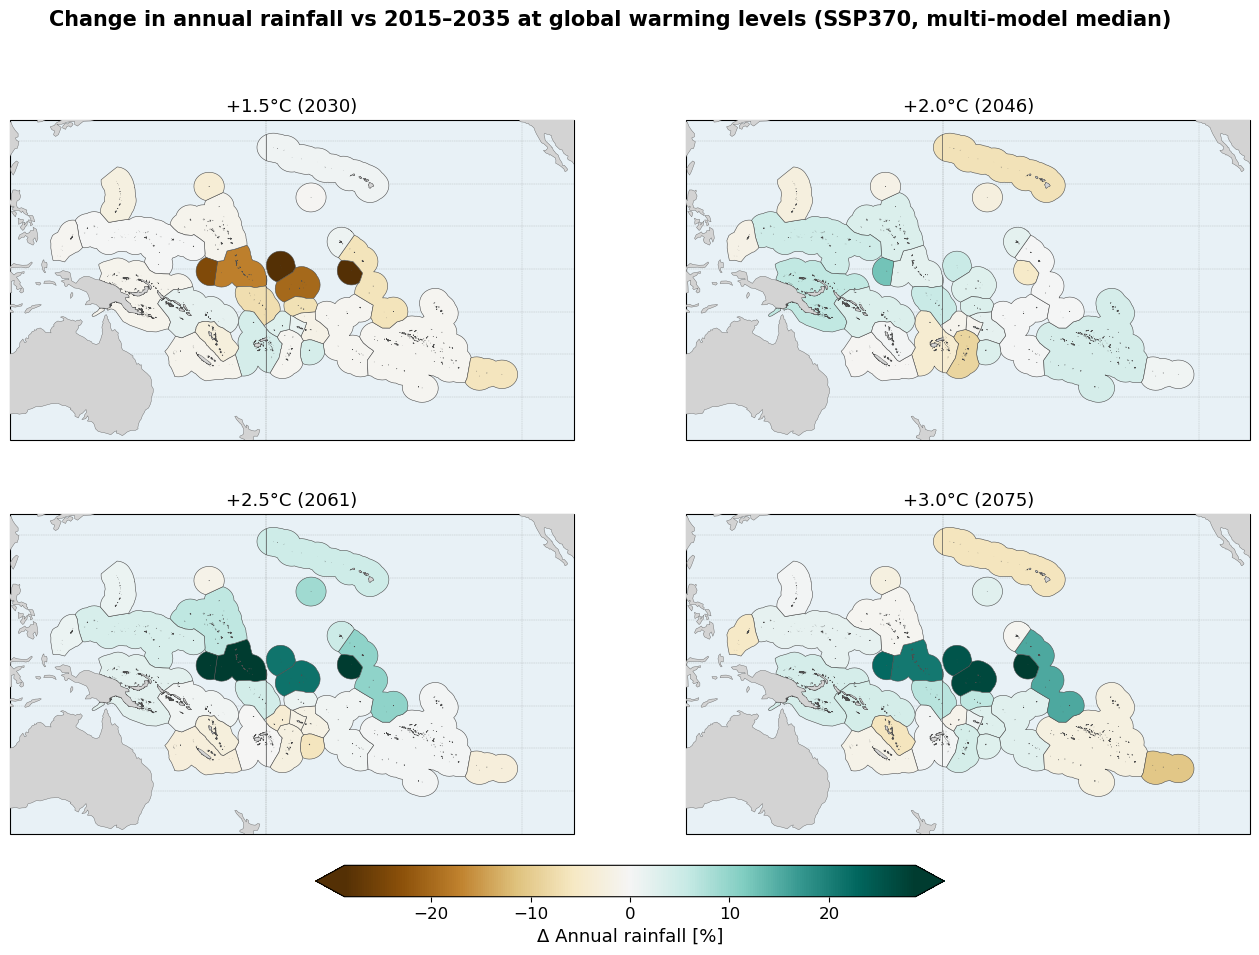

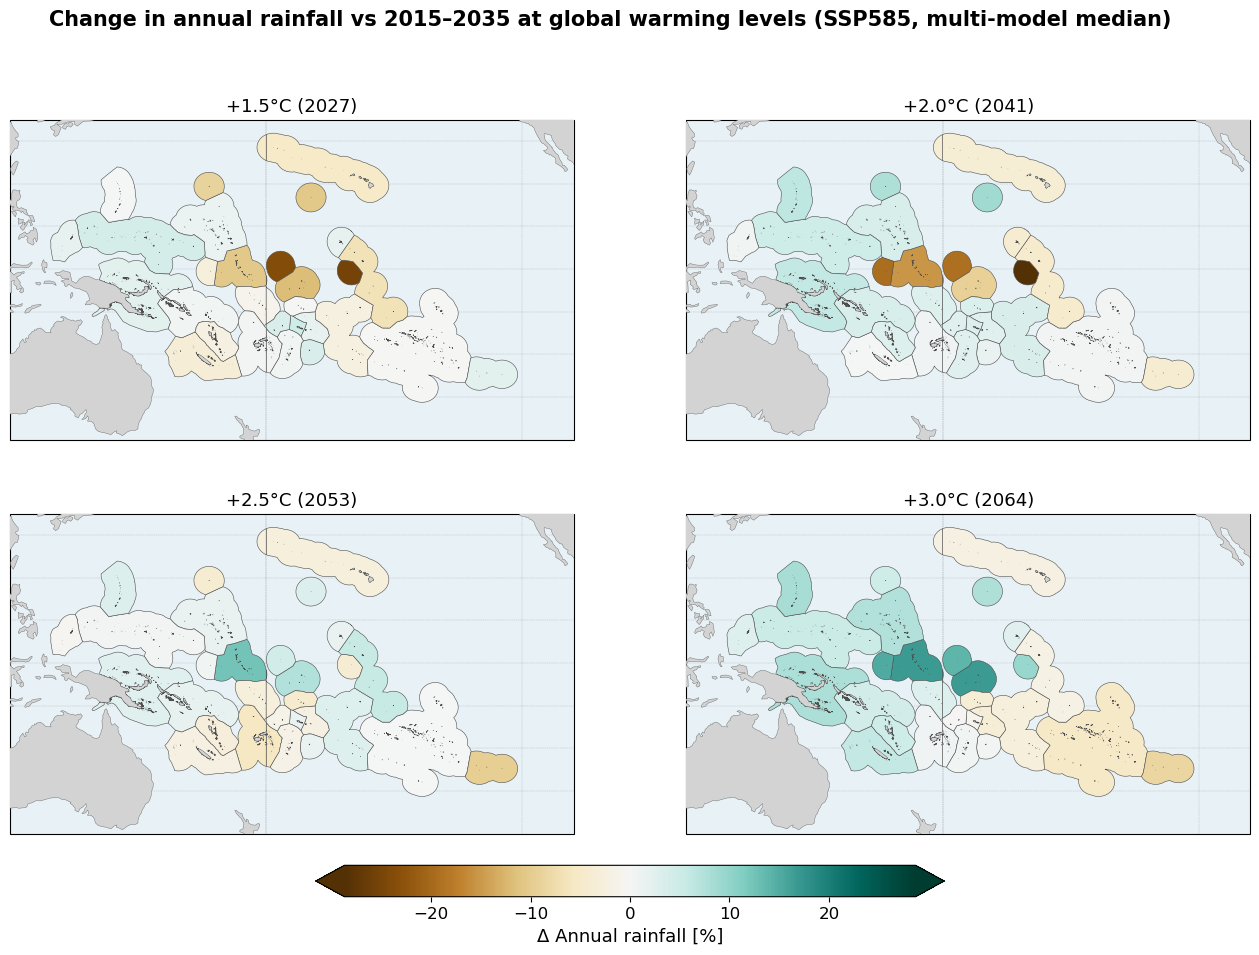

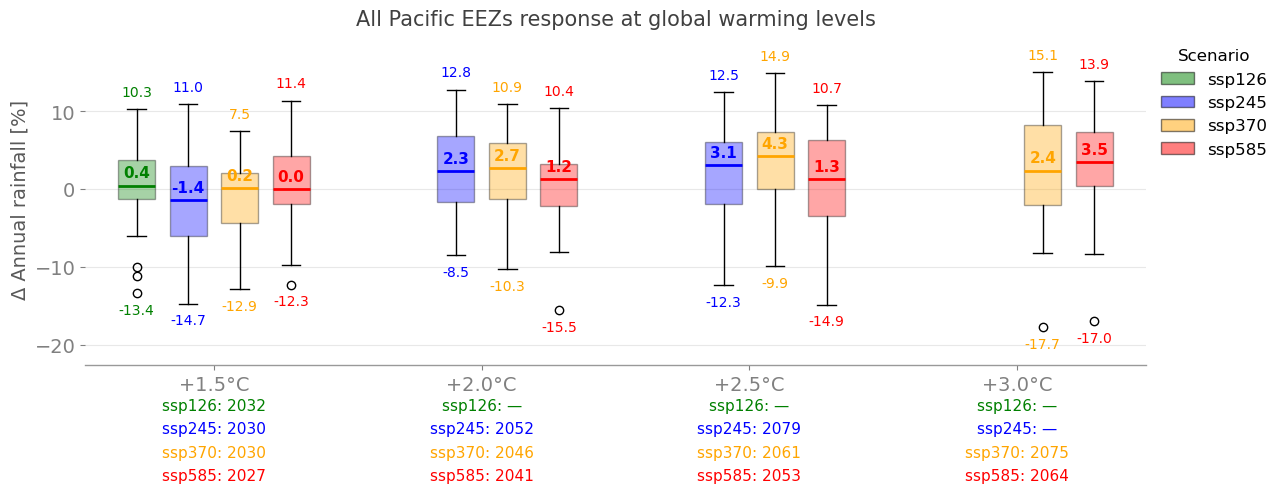

In [4]:
ds = reg.extract_regional_means("pr", eez, ssp_scenarios)
figs, tables = reg.indicator_report(ds, "pr", scenario_info, eez, ssp_scenarios, map_scenario, fig_dir, tables_dir)
glue("pr_fig", figs["levels"], display=False)
reg.show_tables(tables)


## Dry days

Annual number of dry days.

**Dry days: linear trend 2015–2100 of the multi-model median (days/year per decade), by EEZ**

,SSP126,SSP245,SSP370,SSP585
American Samoa,0.14,0.22,0.12,0.40
Cook Islands,0.12,0.09,-0.11,0.19
Fiji,0.16,0.16,-0.18,-0.11
French Polynesia,0.17,0.39,0.95,1.57
Hawaii,0.03,0.20,0.35,0.33
Howland Island and Baker Island,-1.90,-3.45,-4.79,-7.54
Jarvis Island,-1.75,-3.73,-5.48,-8.30
Johnston Atoll,0.19,-0.13,-0.68,-0.55
Kiribati,-2.15,-4.05,-5.37,-7.46
Line Group,-0.88,-1.78,-2.50,-3.19


**Change in dry days vs 2015–2035 at the global warming levels (SSP126, multi-model median, days/year), by EEZ**

,+1.5°C (2032)
region,
American Samoa,-6.3
Cook Islands,0.5
Fiji,-5.1
French Polynesia,-1.1
Hawaii,-2.2
Howland Island and Baker Island,9.1
Jarvis Island,15.2
Johnston Atoll,-2.2
Kiribati,11.1


**Change in dry days vs 2015–2035 at the global warming levels (SSP245, multi-model median, days/year), by EEZ**

,+1.5°C (2030),+2.0°C (2052),+2.5°C (2079)
region,,,
American Samoa,-1.7,-1.7,-1.2
Cook Islands,-3.1,0.8,1.5
Fiji,0.9,-6.2,2.5
French Polynesia,-1.3,2.9,3.4
Hawaii,2.7,0.8,2.9
Howland Island and Baker Island,25.1,-6.5,-1.5
Jarvis Island,21.2,-4.7,-5.1
Johnston Atoll,-4.8,5.5,-2.7
Kiribati,27.9,-22.3,-13.5


... (2 outputs left out)

**Change in dry days vs 2015–2035 at the global warming levels (SSP585, multi-model median, days/year), by EEZ**

,+1.5°C (2027),+2.0°C (2041),+2.5°C (2053),+3.0°C (2064)
region,,,,
American Samoa,-3.8,-6.3,-2.6,1.0
Cook Islands,2.0,-1.6,-2.1,0.9
Fiji,3.0,-4.3,6.2,-0.7
French Polynesia,-1.0,-1.2,2.0,2.6
Hawaii,-2.6,-2.0,1.6,3.5
Howland Island and Baker Island,6.0,7.8,-20.4,-9.7
Jarvis Island,9.4,9.2,-10.4,-12.7
Johnston Atoll,8.2,-7.8,2.4,-9.4
Kiribati,-1.8,3.2,-29.4,-21.2


**Change in dry days vs 2015–2035 at the global warming levels (days/year): spread across models in All Pacific EEZs**

,Region,Scenario,Warming level,Year,Models,Median,P10,P90,Min,Max
0,All Pacific EEZs,SSP126,+1.5°C,2032,30,-1.4,-9.9,4.4,-11.5,11.3
1,All Pacific EEZs,SSP126,+2.0°C,<NA>,0,NaN,NaN,NaN,NaN,NaN
2,All Pacific EEZs,SSP126,+2.5°C,<NA>,0,NaN,NaN,NaN,NaN,NaN
3,All Pacific EEZs,SSP126,+3.0°C,<NA>,0,NaN,NaN,NaN,NaN,NaN
4,All Pacific EEZs,SSP245,+1.5°C,2030,30,1.1,-5.1,8.6,-8.6,15.2
5,All Pacific EEZs,SSP245,+2.0°C,2052,30,-0.9,-6.3,4.5,-13.4,7.6
6,All Pacific EEZs,SSP245,+2.5°C,2079,30,-2.9,-7.9,2.7,-16.1,11.4
7,All Pacific EEZs,SSP245,+3.0°C,<NA>,0,NaN,NaN,NaN,NaN,NaN
8,All Pacific EEZs,SSP370,+1.5°C,2030,30,-0.3,-6.1,8.1,-7.9,11.3
9,All Pacific EEZs,SSP370,+2.0°C,2046,30,-1.3,-6.8,5.9,-10.2,15.1


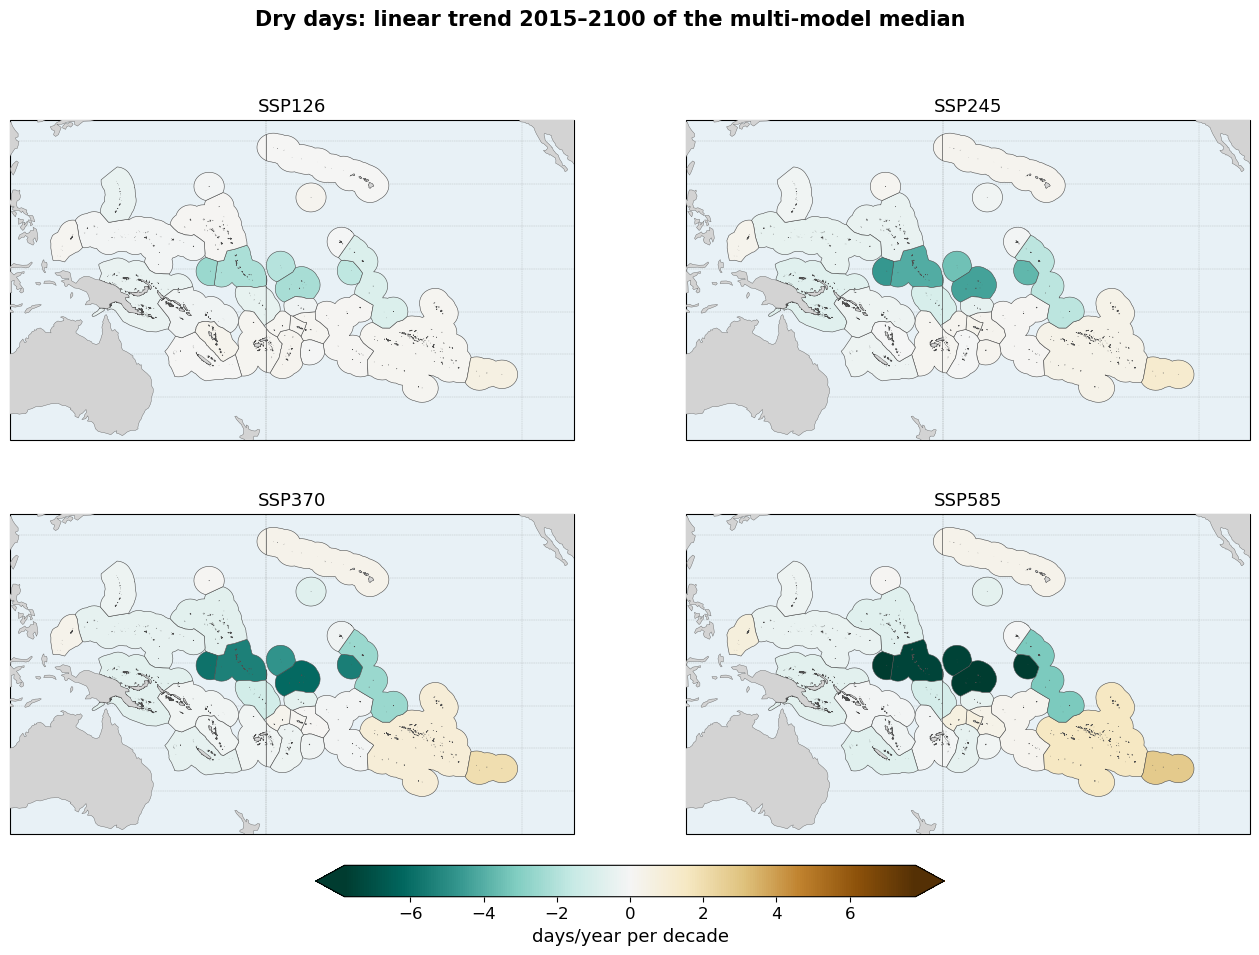

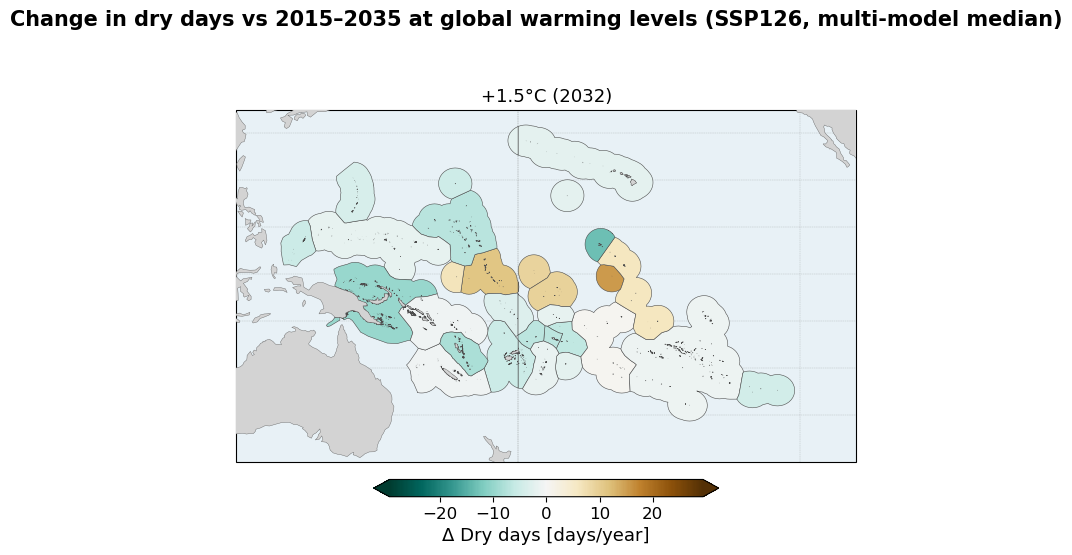

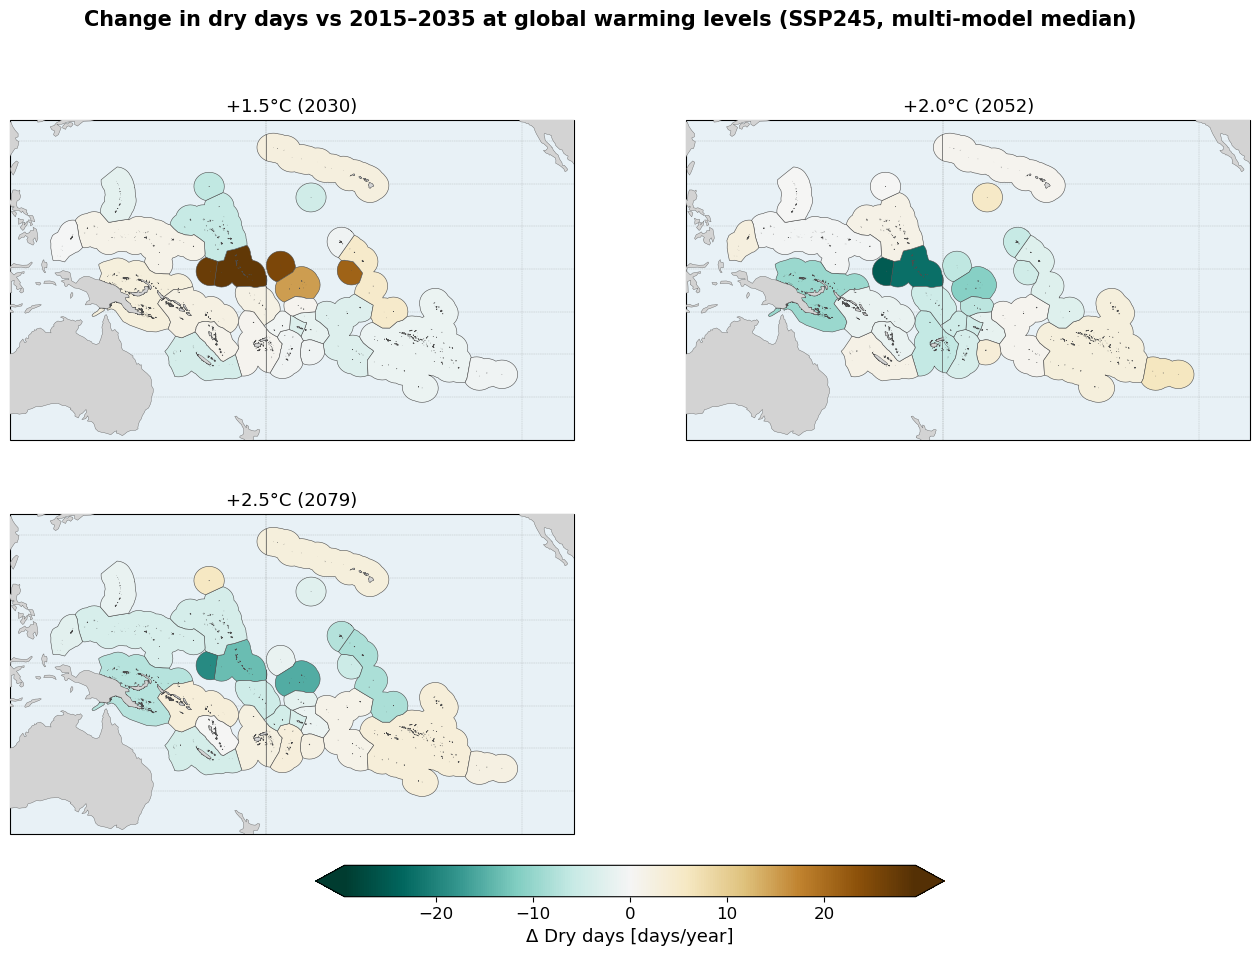

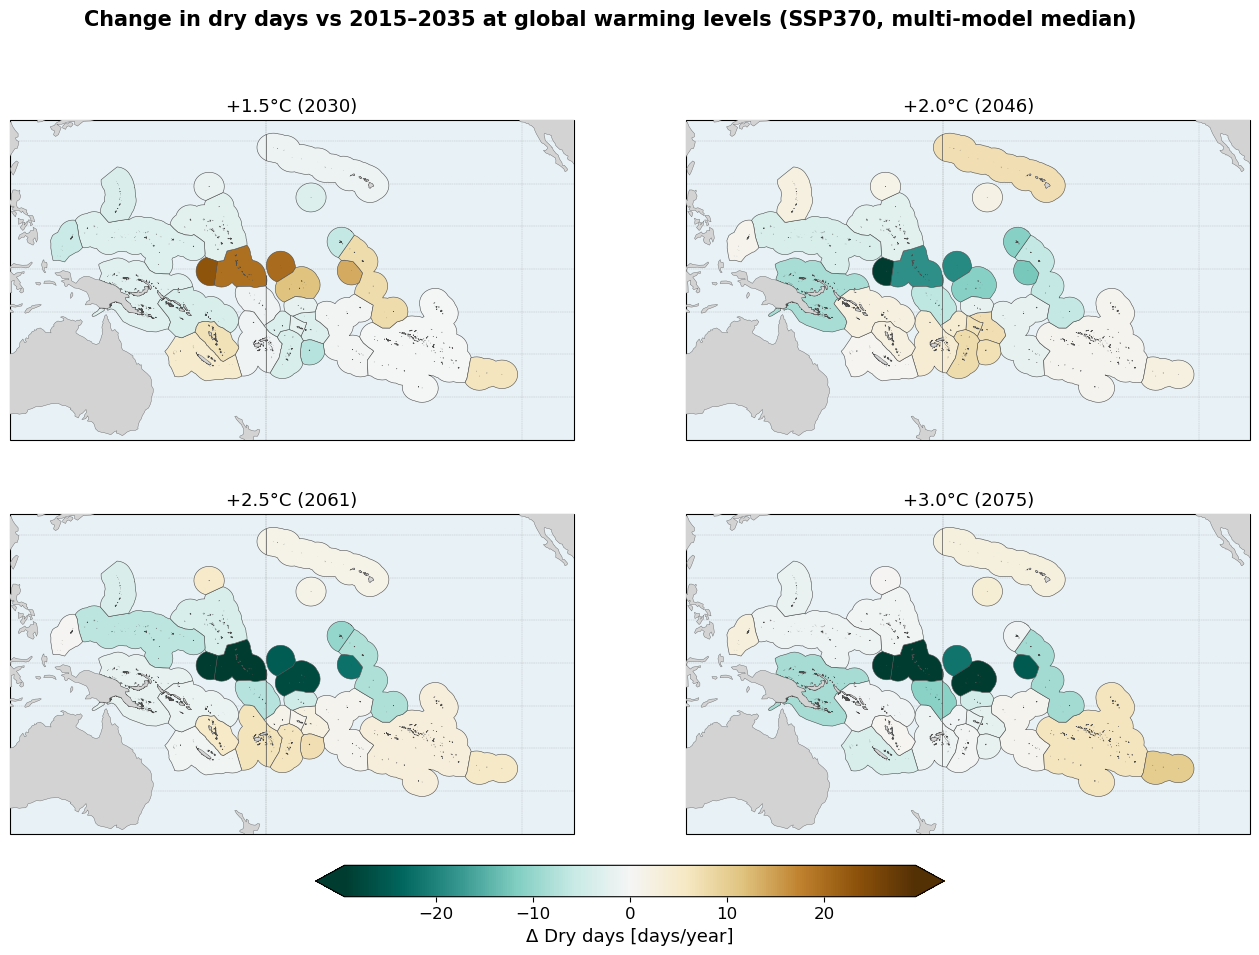

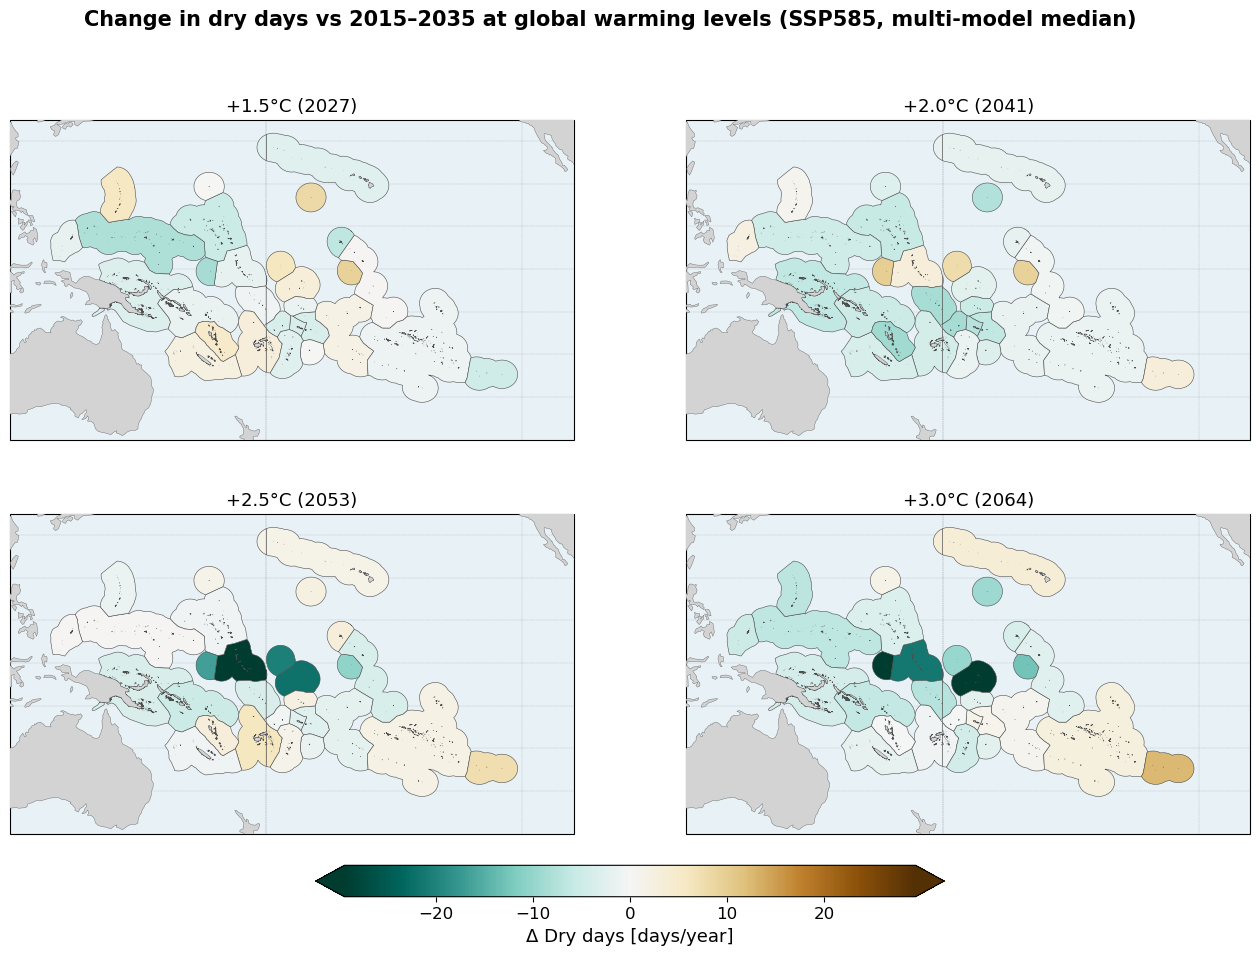

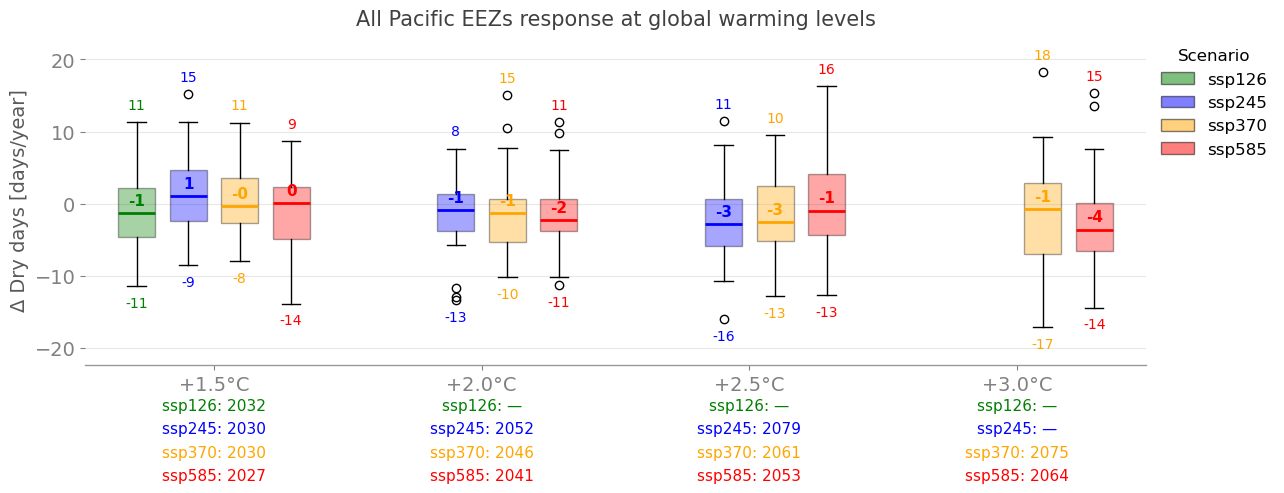

In [5]:
ds = reg.extract_regional_means("dry_days", eez, ssp_scenarios)
figs, tables = reg.indicator_report(ds, "dry_days", scenario_info, eez, ssp_scenarios, map_scenario, fig_dir, tables_dir)
reg.show_tables(tables)


## Heavy-rainfall days

Annual number of heavy-rainfall days.

**Heavy-rainfall days: linear trend 2015–2100 of the multi-model median (days/year per decade), by EEZ**

,SSP126,SSP245,SSP370,SSP585
American Samoa,-0.02,0.09,0.14,0.13
Cook Islands,0.05,0.12,0.23,0.18
Fiji,-0.06,-0.05,0.01,-0.05
French Polynesia,0.04,0.06,0.03,-0.14
Hawaii,-0.06,-0.17,0.00,0.02
Howland Island and Baker Island,0.63,1.63,2.59,3.78
Jarvis Island,0.87,1.84,3.23,5.11
Johnston Atoll,-0.04,0.04,0.43,0.62
Kiribati,0.53,1.51,2.31,3.26
Line Group,0.51,0.91,1.50,2.19


**Change in heavy-rainfall days vs 2015–2035 at the global warming levels (SSP126, multi-model median, days/year), by EEZ**

,+1.5°C (2032)
region,
American Samoa,-0.1
Cook Islands,-1.2
Fiji,0.9
French Polynesia,-1.2
Hawaii,-1.3
Howland Island and Baker Island,-8.4
Jarvis Island,-14.4
Johnston Atoll,-1.4
Kiribati,-7.6


**Change in heavy-rainfall days vs 2015–2035 at the global warming levels (SSP245, multi-model median, days/year), by EEZ**

,+1.5°C (2030),+2.0°C (2052),+2.5°C (2079)
region,,,
American Samoa,-1.5,1.2,3.0
Cook Islands,-0.5,0.6,0.9
Fiji,-1.8,0.9,-1.0
French Polynesia,-0.5,-0.8,0.4
Hawaii,0.0,-1.5,-1.2
Howland Island and Baker Island,-13.0,2.9,6.7
Jarvis Island,-13.0,-3.5,3.7
Johnston Atoll,1.1,-3.7,2.1
Kiribati,-8.3,1.7,6.9


... (2 outputs left out)

**Change in heavy-rainfall days vs 2015–2035 at the global warming levels (SSP585, multi-model median, days/year), by EEZ**

,+1.5°C (2027),+2.0°C (2041),+2.5°C (2053),+3.0°C (2064)
region,,,,
American Samoa,1.7,-0.4,1.2,-1.2
Cook Islands,-1.0,1.6,1.5,-0.6
Fiji,-0.4,-0.8,-1.3,0.2
French Polynesia,-0.3,0.2,1.0,-0.8
Hawaii,-1.0,-0.9,-1.1,-0.2
Howland Island and Baker Island,-10.1,-6.9,1.9,0.2
Jarvis Island,-9.4,-10.6,5.8,1.5
Johnston Atoll,-2.5,3.1,0.2,3.2
Kiribati,-3.6,-6.8,1.5,4.9


**Change in heavy-rainfall days vs 2015–2035 at the global warming levels (days/year): spread across models in All Pacific EEZs**

,Region,Scenario,Warming level,Year,Models,Median,P10,P90,Min,Max
0,All Pacific EEZs,SSP126,+1.5°C,2032,30,-1.0,-3.8,3.6,-5.5,5.2
1,All Pacific EEZs,SSP126,+2.0°C,<NA>,0,NaN,NaN,NaN,NaN,NaN
2,All Pacific EEZs,SSP126,+2.5°C,<NA>,0,NaN,NaN,NaN,NaN,NaN
3,All Pacific EEZs,SSP126,+3.0°C,<NA>,0,NaN,NaN,NaN,NaN,NaN
4,All Pacific EEZs,SSP245,+1.5°C,2030,30,-1.5,-4.0,3.6,-5.6,6.7
5,All Pacific EEZs,SSP245,+2.0°C,2052,30,1.0,-1.8,4.6,-5.2,7.8
6,All Pacific EEZs,SSP245,+2.5°C,2079,30,1.5,-2.9,5.6,-4.2,8.0
7,All Pacific EEZs,SSP245,+3.0°C,<NA>,0,NaN,NaN,NaN,NaN,NaN
8,All Pacific EEZs,SSP370,+1.5°C,2030,30,-0.9,-3.8,1.7,-7.6,3.7
9,All Pacific EEZs,SSP370,+2.0°C,2046,30,0.8,-2.2,5.4,-5.0,8.6


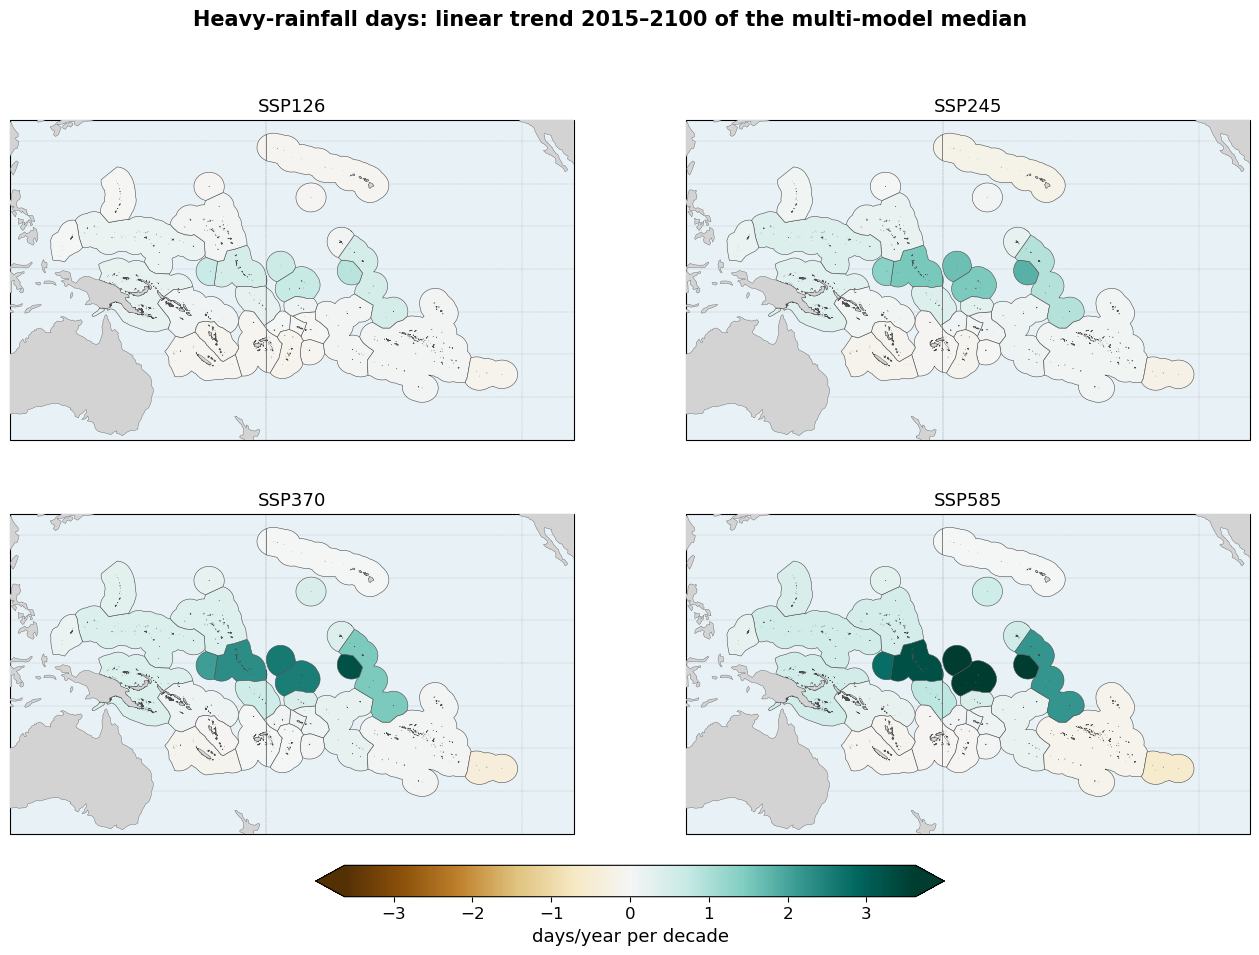

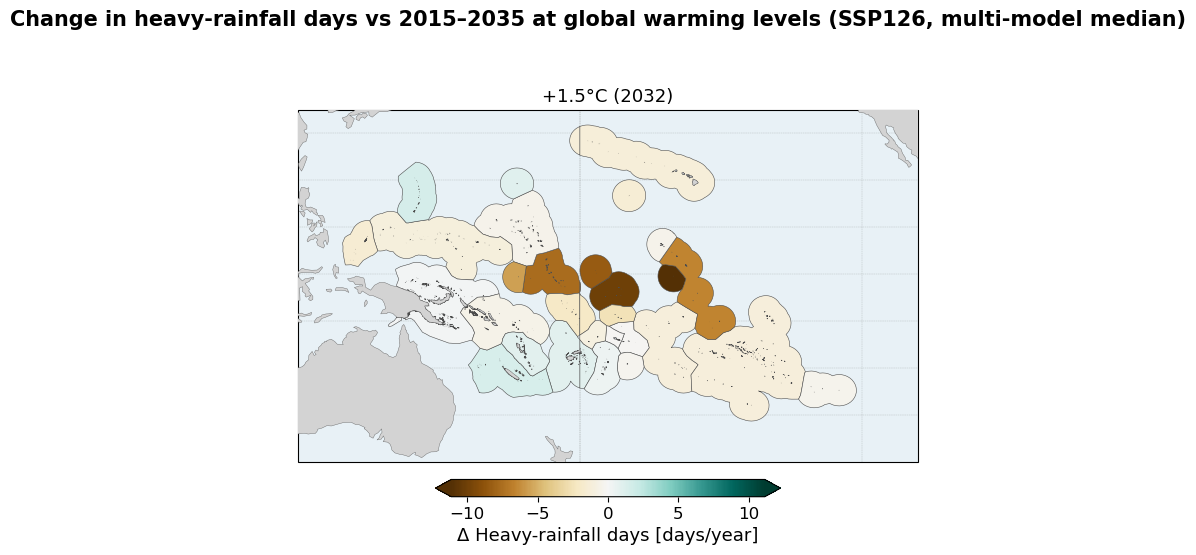

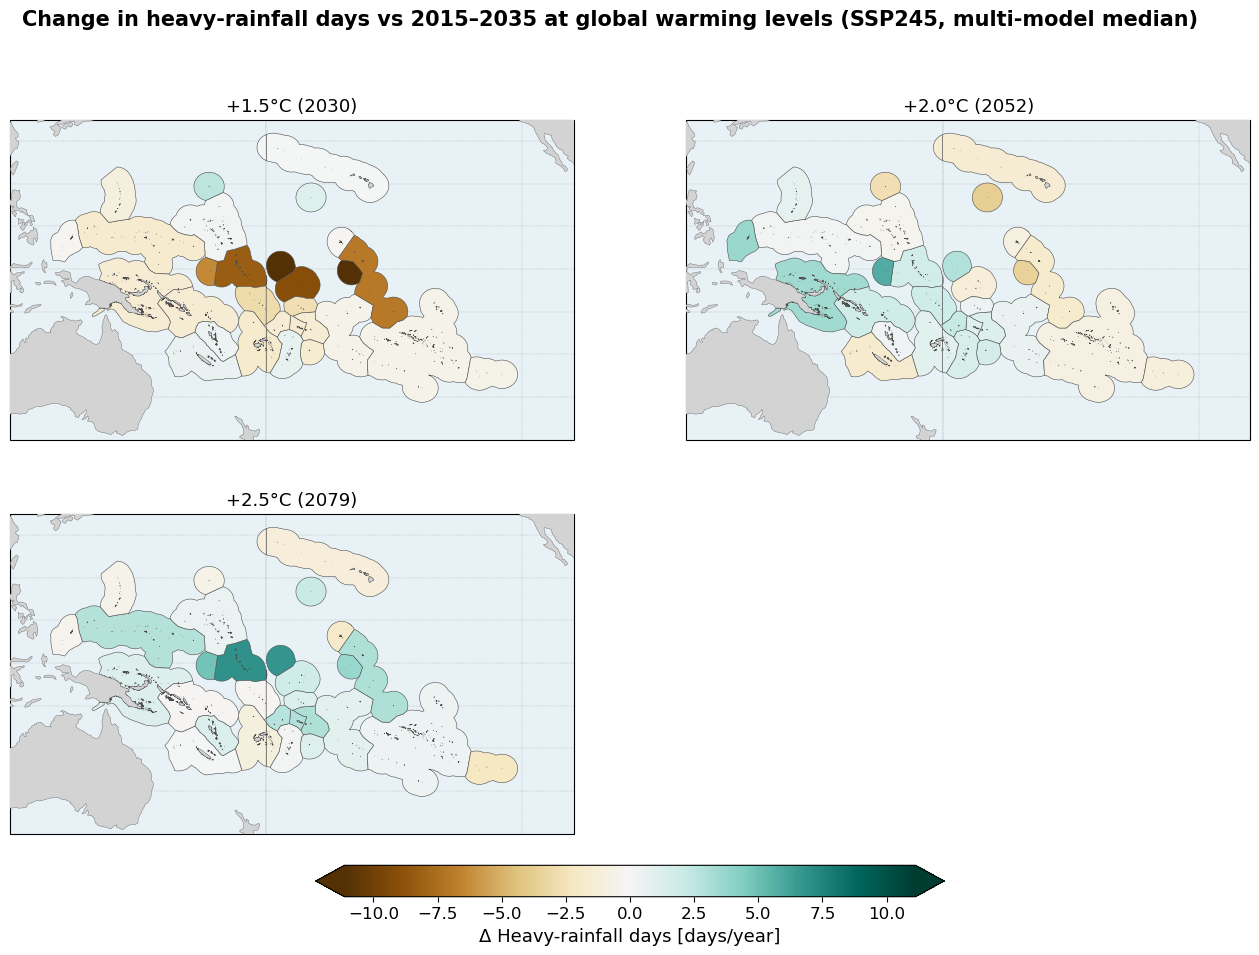

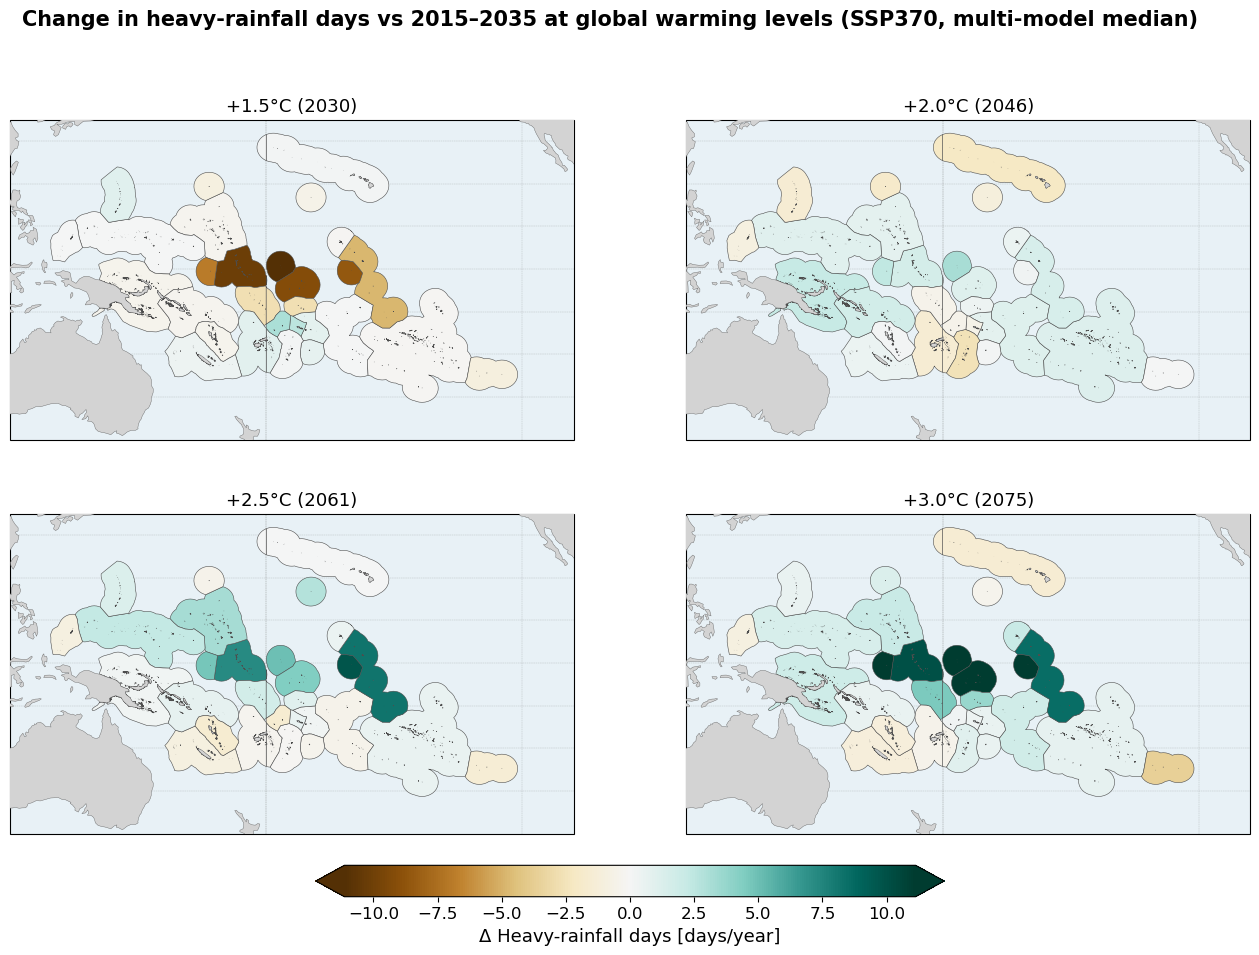

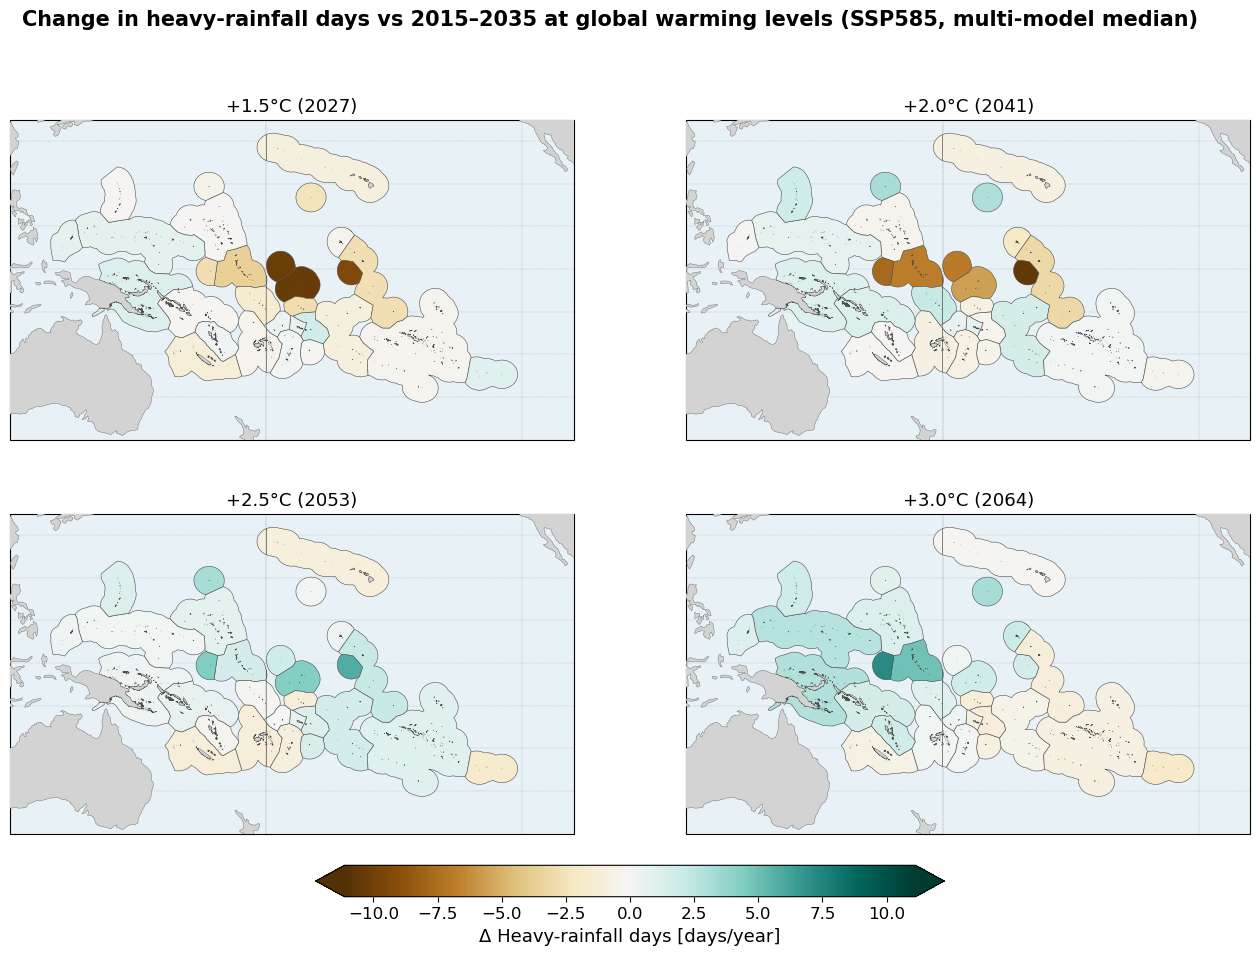

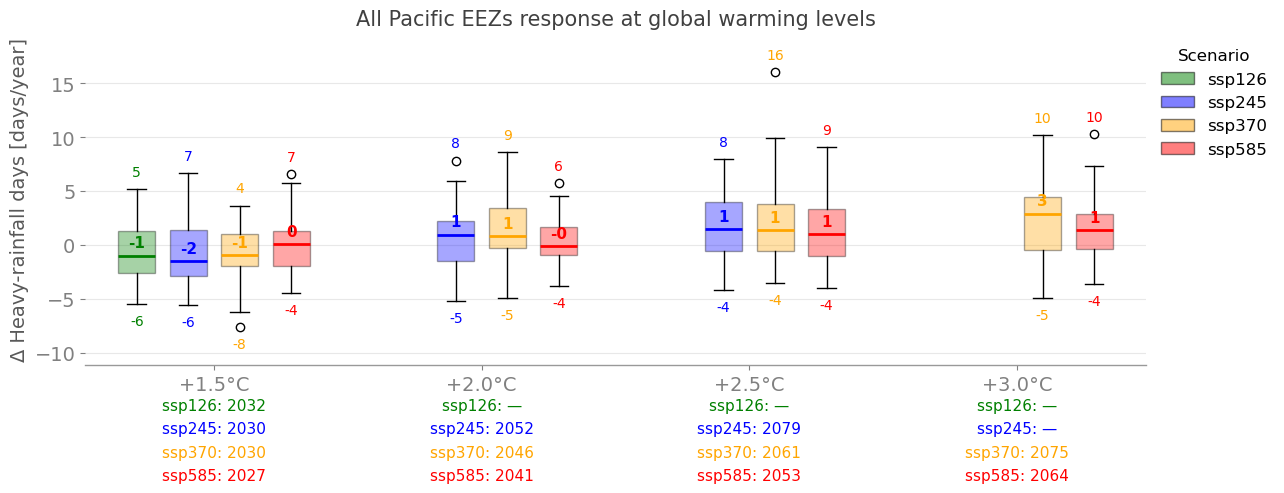

In [6]:
ds = reg.extract_regional_means("heavyraindays", eez, ssp_scenarios)
figs, tables = reg.indicator_report(ds, "heavyraindays", scenario_info, eez, ssp_scenarios, map_scenario, fig_dir, tables_dir)
reg.show_tables(tables)


## Annual maximum daily rainfall

Annual maximum daily rainfall, change in %.

**Annual maximum daily rainfall: linear trend 2015–2100 of the multi-model median (% per decade), by EEZ**

,SSP126,SSP245,SSP370,SSP585
American Samoa,0.530,1.057,1.695,2.232
Cook Islands,0.596,0.991,1.798,2.222
Fiji,0.197,0.915,1.353,2.085
French Polynesia,0.466,1.147,1.671,1.858
Hawaii,-0.016,0.306,1.379,1.991
Howland Island and Baker Island,2.588,4.655,7.491,10.603
Jarvis Island,2.201,6.224,11.299,16.316
Johnston Atoll,-0.208,0.373,2.159,3.223
Kiribati,1.660,4.017,5.645,7.780
Line Group,1.153,2.463,3.881,5.230


**Change in annual maximum daily rainfall vs 2015–2035 at the global warming levels (SSP126, multi-model median, %), by EEZ**

,+1.5°C (2032)
region,
American Samoa,-1.76
Cook Islands,-0.19
Fiji,3.65
French Polynesia,-3.39
Hawaii,-3.77
Howland Island and Baker Island,-18.97
Jarvis Island,-38.02
Johnston Atoll,-12.33
Kiribati,-14.48


**Change in annual maximum daily rainfall vs 2015–2035 at the global warming levels (SSP245, multi-model median, %), by EEZ**

,+1.5°C (2030),+2.0°C (2052),+2.5°C (2079)
region,,,
American Samoa,-6.94,-0.71,13.21
Cook Islands,0.65,4.23,7.21
Fiji,0.02,5.12,4.17
French Polynesia,-2.11,3.21,1.64
Hawaii,0.37,-2.19,12.78
Howland Island and Baker Island,-21.19,2.62,28.70
Jarvis Island,-49.27,13.68,12.44
Johnston Atoll,3.62,-10.09,17.86
Kiribati,-11.77,6.72,23.28


... (2 outputs left out)

**Change in annual maximum daily rainfall vs 2015–2035 at the global warming levels (SSP585, multi-model median, %), by EEZ**

,+1.5°C (2027),+2.0°C (2041),+2.5°C (2053),+3.0°C (2064)
region,,,,
American Samoa,-0.94,1.40,6.10,2.18
Cook Islands,-2.14,4.00,3.97,2.30
Fiji,1.30,-3.84,9.20,4.07
French Polynesia,2.13,4.57,9.34,4.83
Hawaii,3.68,3.35,0.53,6.17
Howland Island and Baker Island,-12.48,-15.98,0.15,23.51
Jarvis Island,-18.53,-16.74,2.77,12.17
Johnston Atoll,-8.81,8.47,6.99,13.19
Kiribati,-6.41,-7.06,9.21,16.68


**Change in annual maximum daily rainfall vs 2015–2035 at the global warming levels (%): spread across models in All Pacific EEZs**

,Region,Scenario,Warming level,Year,Models,Median,P10,P90,Min,Max
0,All Pacific EEZs,SSP126,+1.5°C,2032,30,-1.40,-10.90,6.56,-21.35,8.44
1,All Pacific EEZs,SSP126,+2.0°C,<NA>,0,NaN,NaN,NaN,NaN,NaN
2,All Pacific EEZs,SSP126,+2.5°C,<NA>,0,NaN,NaN,NaN,NaN,NaN
3,All Pacific EEZs,SSP126,+3.0°C,<NA>,0,NaN,NaN,NaN,NaN,NaN
4,All Pacific EEZs,SSP245,+1.5°C,2030,30,-1.77,-10.64,9.91,-21.32,14.68
5,All Pacific EEZs,SSP245,+2.0°C,2052,30,5.19,-6.20,17.92,-12.00,25.87
6,All Pacific EEZs,SSP245,+2.5°C,2079,30,6.66,-1.08,26.64,-9.15,52.70
7,All Pacific EEZs,SSP245,+3.0°C,<NA>,0,NaN,NaN,NaN,NaN,NaN
8,All Pacific EEZs,SSP370,+1.5°C,2030,30,-1.07,-9.95,5.14,-24.58,19.68
9,All Pacific EEZs,SSP370,+2.0°C,2046,30,6.73,-4.67,14.08,-24.60,19.43


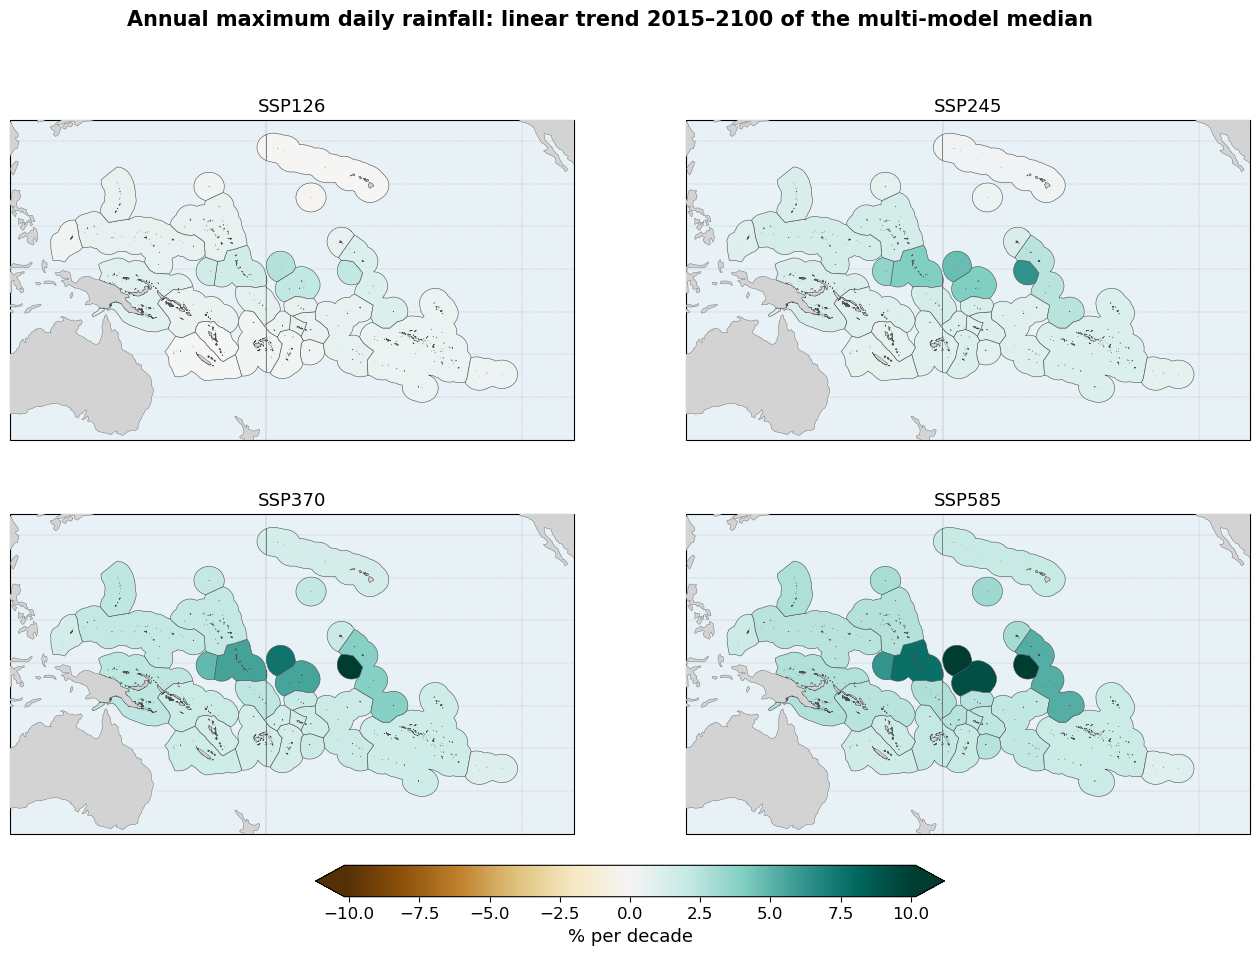

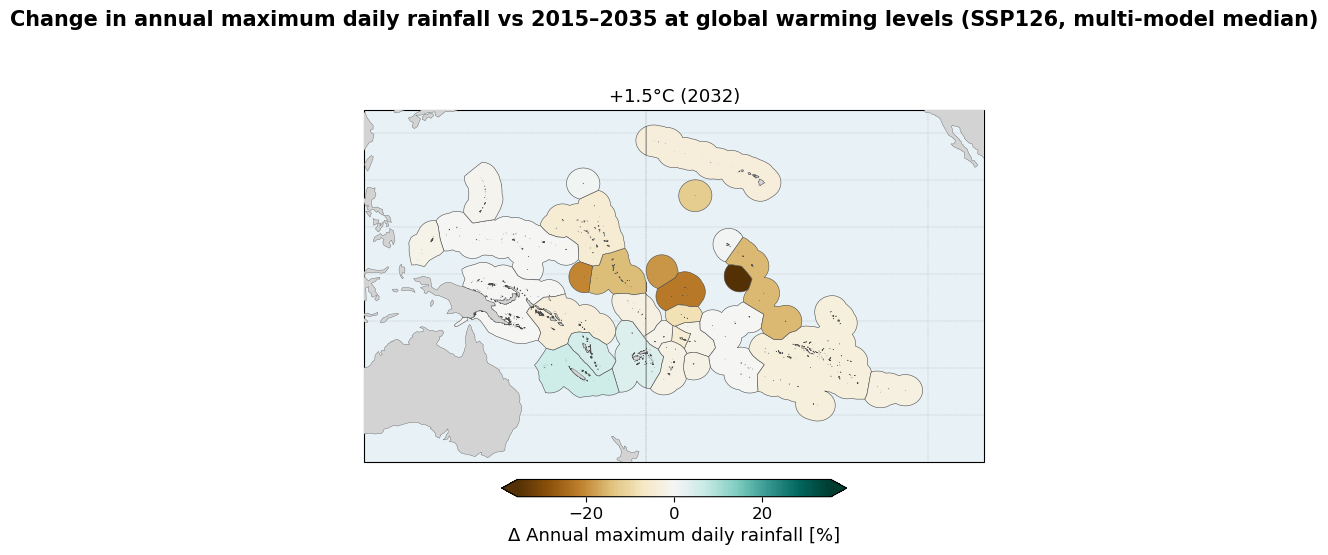

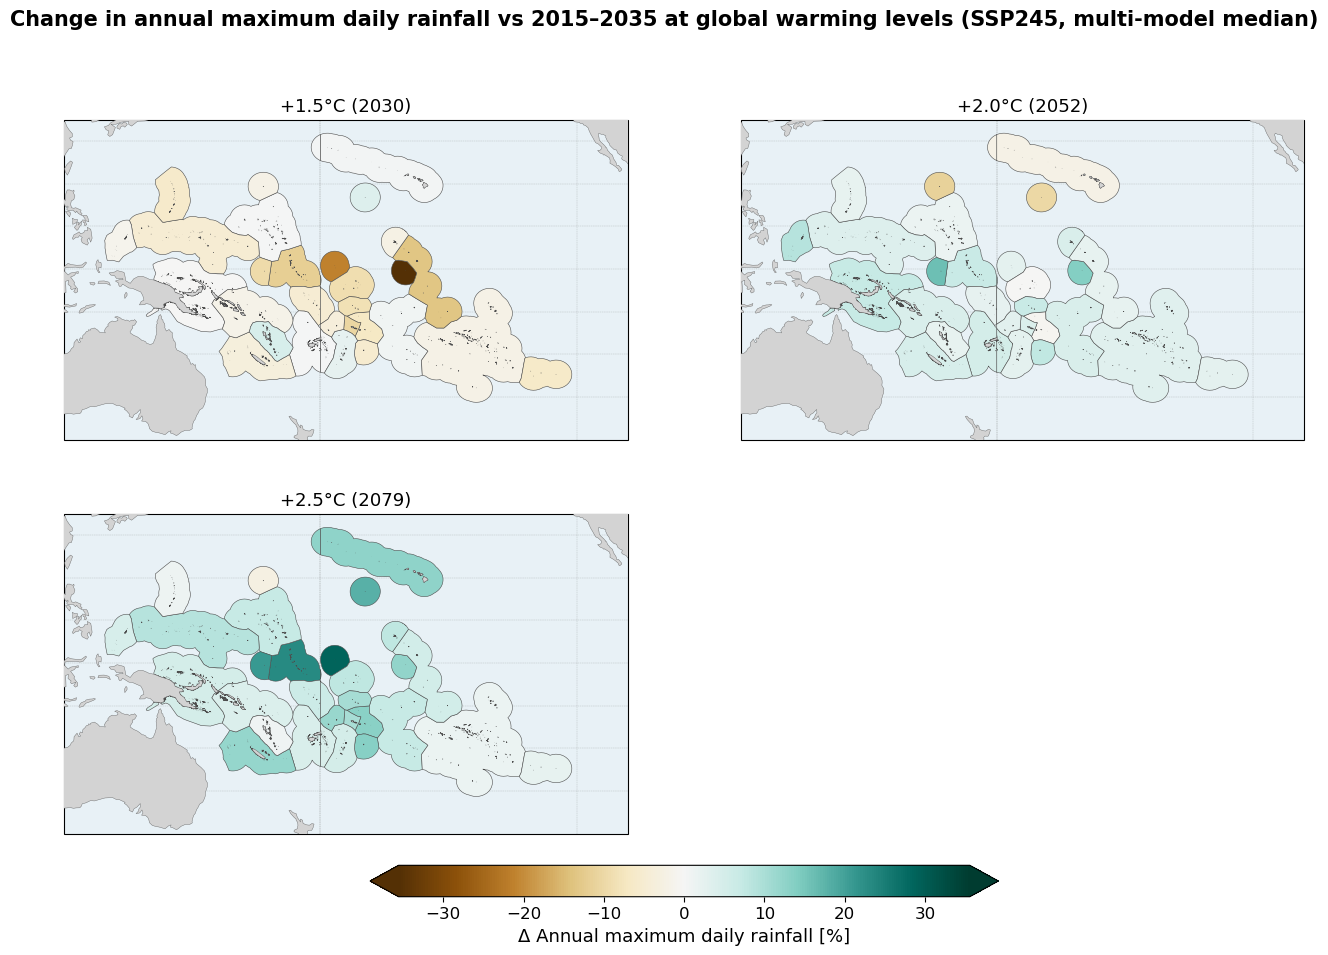

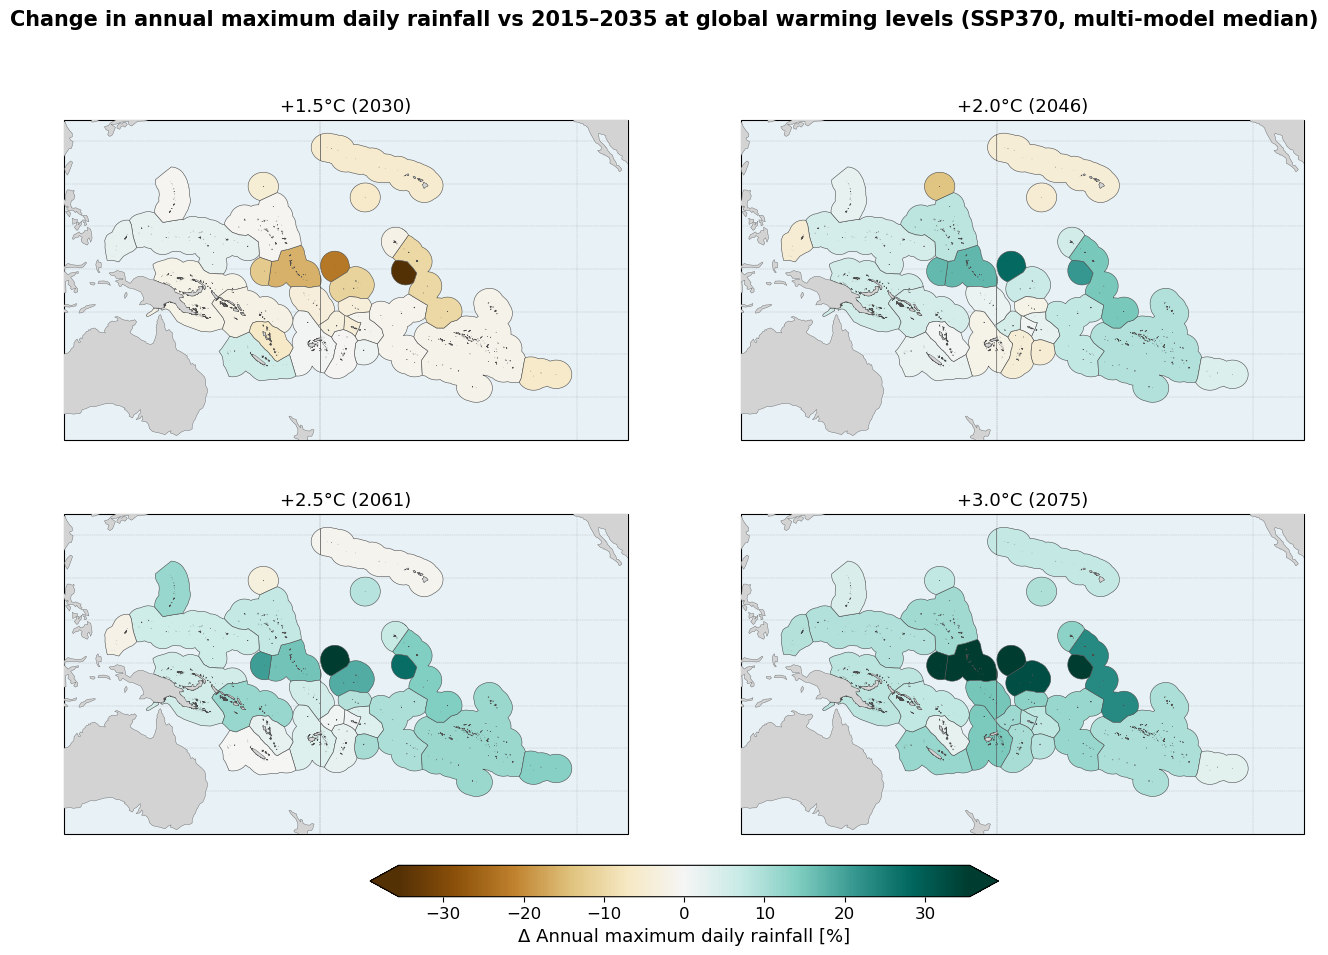

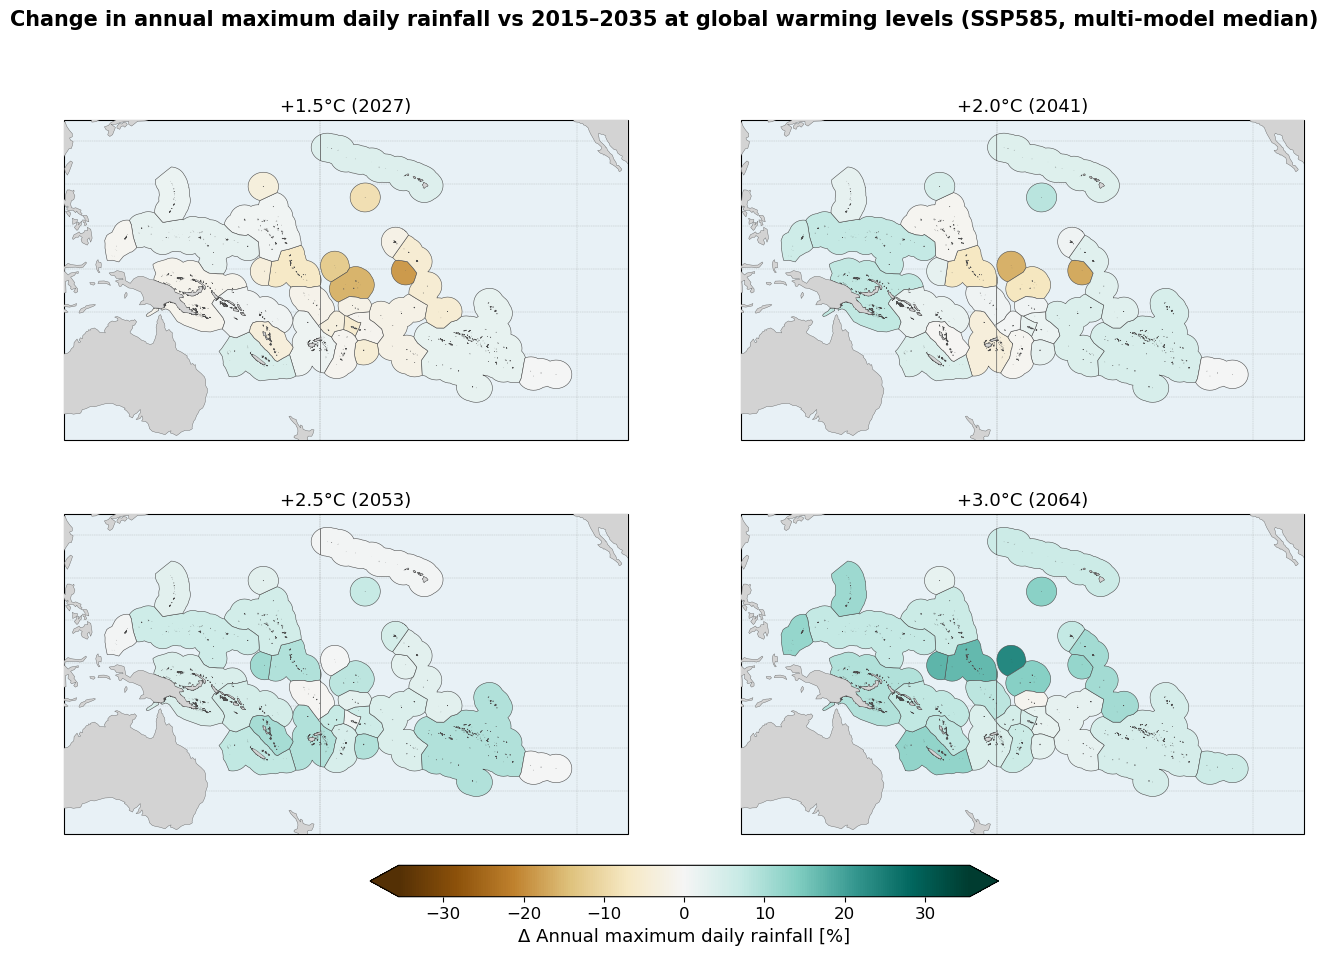

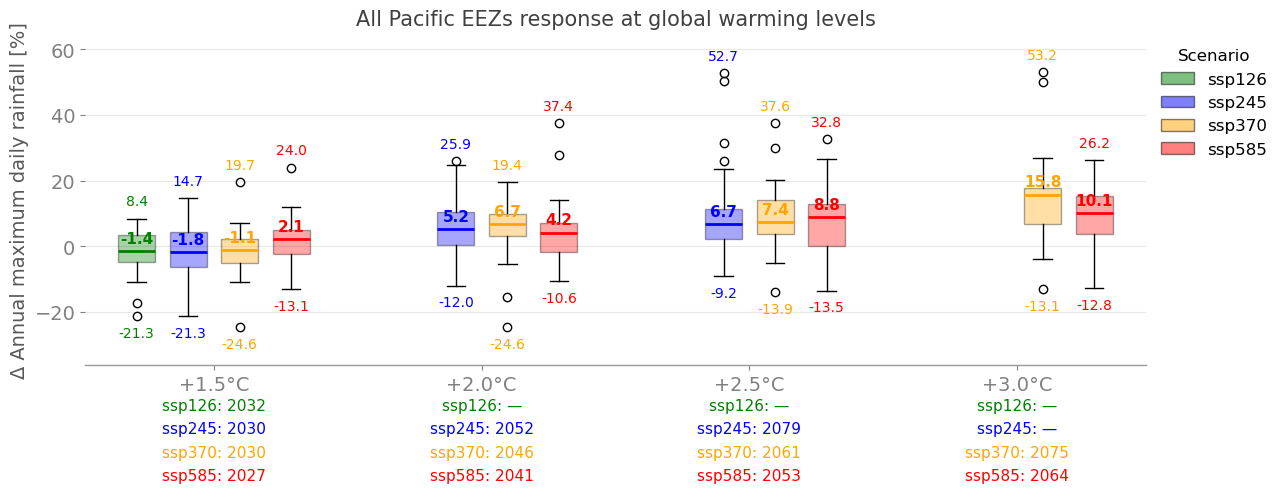

In [7]:
ds = reg.extract_regional_means("yearmax", eez, ssp_scenarios)
figs, tables = reg.indicator_report(ds, "yearmax", scenario_info, eez, ssp_scenarios, map_scenario, fig_dir, tables_dir)
reg.show_tables(tables)
